# 1. Introduktion och syfte
Syftet med analysen är att undersöka företagets försäljning och identifiera mönster som kan användas som beslutsunderlag inför kommande planeringar. Vi analyserar försäljningen utifrån produktkategorier, geografiska områden, tidsperioder och ordervärden samt undersöker eventuella avvikelser.

# 2. Datainläsning och datakontroll
Vi använder datasetet ecommerce_sales.csv, som innehåller information om beställningar, datu, städer, produktkategorier, priser, antal sålda enheter och intäkter.

Inledningsvis läser vi in datamaterialet med Pandas och kontrollerar dess struktur, datatyper och eventuella saknade värden. 

In [1]:
import pandas as pd
df=pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [2]:
df.info()
print("\nSaknade värden per kolumn:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB

Saknade värden per kolumn:
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64


# 3. Övergripande nyckeltal
Vi beräknar företagets totala omsättning, antal sålda enheter, antal unika beställningar och genomsnittlig ordervärde (AOV) för att få en övergripande bild av försäljningen. 

In [3]:
total_intakt=df["revenue"].sum()
total_antal_salda=df["units"].sum()
antal_ordrar=df["order_id"].nunique()
aov=total_intakt/antal_ordrar
print(f"Total omsättning: {total_intakt} kr")
print(f"Antal sålda enheter: {total_antal_salda}")
print(f"Antal beställningar: {antal_ordrar}")
print(f"Genomsnittlig ordervärde (AOV): {aov} kr")

Total omsättning: 3502767.2300000004 kr
Antal sålda enheter: 7463
Antal beställningar: 2500
Genomsnittlig ordervärde (AOV): 1401.1068920000002 kr


# 4. Vad säljer vi?
Vi analyserar vilka produktkategorier som genererar störst omsättning och jämför försäljningsvolymen mellan kategorierna. Vi undersöker även genomsnittlig intäkt per såld enhet och indentifierar de tre största kategorierna efter omsättning.


In [4]:
#Intäkter per kategori samt andel intäkter per kategori.
intakter_per_kategori=df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(intakter_per_kategori.round(0))
total_intakt=df["revenue"].sum()
andel_intakter_per_kategori=(intakter_per_kategori/total_intakt)*100
print(andel_intakter_per_kategori.round(0))

category
Electronics    1364228.0
Sports          734653.0
Clothing        586745.0
Home            511071.0
Beauty          163054.0
Toys            143016.0
Name: revenue, dtype: float64
category
Electronics    39.0
Sports         21.0
Clothing       17.0
Home           15.0
Beauty          5.0
Toys            4.0
Name: revenue, dtype: float64


In [5]:
#Antal sålda per kategori samt andel sålda per kategori.
antal_salda_per_kategori=df.groupby("category")["units"].sum().sort_values(ascending=False)
print(antal_salda_per_kategori)
totalt_antal_salda=df["units"].sum()
andel_salda_per_kategori=(antal_salda_per_kategori/totalt_antal_salda)*100
print(andel_salda_per_kategori.round(0))

category
Electronics    1753
Clothing       1655
Sports         1401
Home           1278
Toys            717
Beauty          659
Name: units, dtype: int64
category
Electronics    23.0
Clothing       22.0
Sports         19.0
Home           17.0
Toys           10.0
Beauty          9.0
Name: units, dtype: float64


In [6]:
#Medelintäkt per såld enhet.
medel_intakt_per_enhet=intakter_per_kategori/antal_salda_per_kategori
medel_intakt_per_enhet=medel_intakt_per_enhet.sort_values(ascending=False).round(0)
print(medel_intakt_per_enhet)

category
Electronics    778.0
Sports         524.0
Home           400.0
Clothing       355.0
Beauty         247.0
Toys           199.0
dtype: float64


### 4.1 Visualisering av försäljningen
För att tydliggöra försäljningsresultaten visualiseras den totala intäkten och antalet sålda enheter per produktkategori i två stapeldiagram.

Diagrammen gör det möjligt att jämföra kategoriernas omsättning och försäljningsvolym.

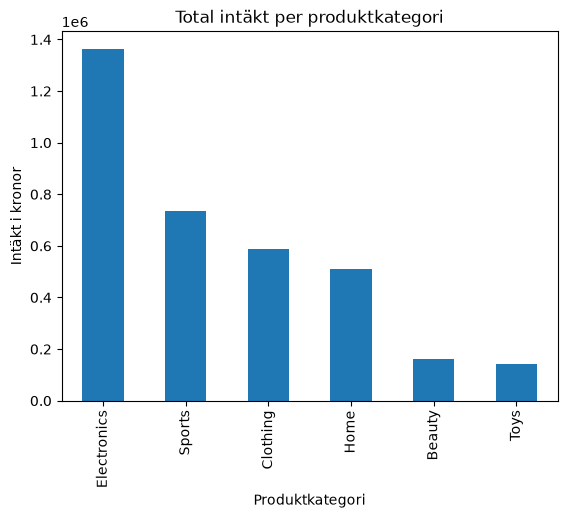

In [7]:
import matplotlib.pyplot as plt
intakter_per_kategori.plot(kind="bar")
plt.title("Total intäkt per produktkategori")
plt.xlabel("Produktkategori")
plt.ylabel("Intäkt i kronor")
plt.show()

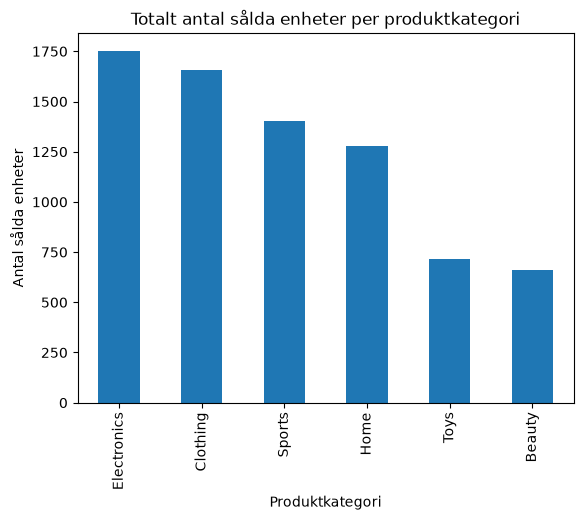

In [8]:
antal_salda_per_kategori.plot(kind="bar")
plt.title("Totalt antal sålda enheter per produktkategori")
plt.xlabel("Produktkategori")
plt.ylabel("Antal sålda enheter")
plt.show()

# 5. Var säljer vi?

# 6. När säljer vi?


# 7. Hur ser en typisk order ut?

# 8. Eventuella avvikelser

# 9. Sammanfattning och rekommendationer


In [9]:
import sys, os
sys.path.append(os.path.abspath(".."))

import src.io_utils as io_utils
import src.metrics as metrics
import src.viz as viz

In [10]:
dat = io_utils.load_data(file_path="../data/ecommerce_sales.csv")

In [11]:
aov = metrics.calc_aov(dat)
print(aov)

1401.11


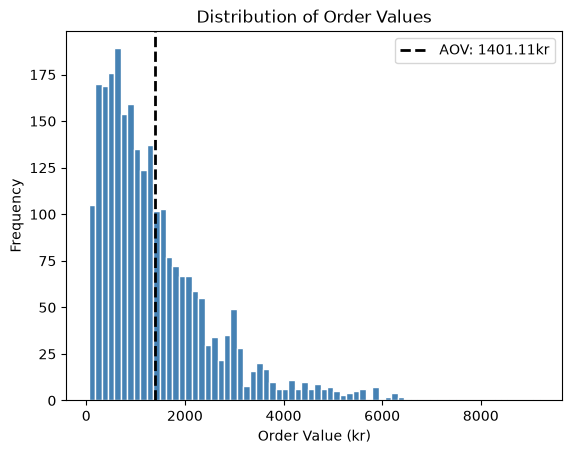

In [12]:
viz.aov_plot(dat)

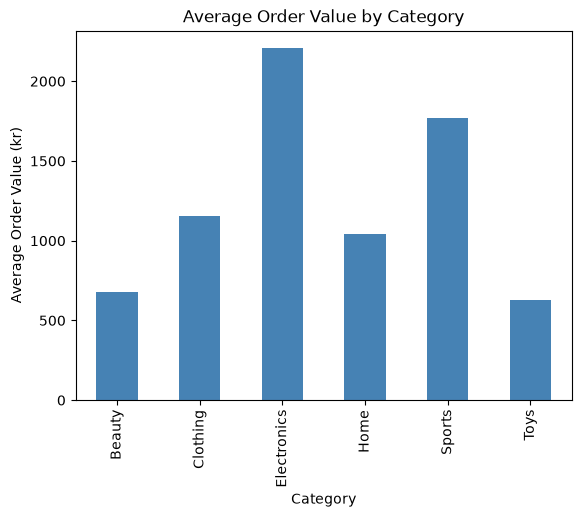

In [13]:
viz.aov_by_cat_plot(dat)

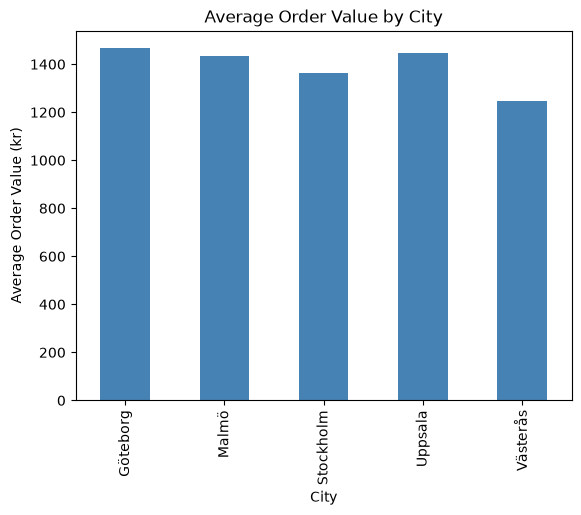

In [14]:
viz.aov_by_cat_plot(dat, category_col="city")